# 모듈 6. JPM 구조화 상품군 분석

**질문**: JP Morgan은 어떤 구조화 상품을, 누구를 통해, 어떤 조건과 마진으로 팔고 있는가?

| 절 | 질문 |
|---|---|
| 1 | 무엇을 얼마나 파나 (상품군·발행 규모) |
| 2 | 누구를 통해 파나 (판매 채널) |
| 3 | 무엇에 연동하나 (기초자산) |
| 4 | 어떤 조건인가 (오토콜 쿠폰·배리어·빈도) |
| 5 | 얼마나 남기나 (추정가치로 본 발행 마진) |
| 6 | 시간에 따라 어떻게 변하나 |
| 7 | 경쟁사 분석 메모 → 모듈 7 신상품 설계의 출발점 |

**데이터**: 모듈 3의 전체 기간 DB (`data/aifinance_full.duckdb`). 2026년 7월 29일 ~ 11월 10일 제출 공시에서 추출한 상품입니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aifinance.analysis import FAMILY_KO, load_products
from aifinance.plotting import setup_korean_font

setup_korean_font()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

df = load_products()
print(f"상품 {len(df):,}개 | 가격결정일 {df.pricing_date.min():%Y-%m-%d} ~ {df.pricing_date.max():%Y-%m-%d} | 총 발행액 ${df.principal_amount_usd.sum() / 1e9:.2f}B")

상품 3,146개 | 가격결정일 2026-06-25 ~ 2026-11-09 | 총 발행액 $8.90B


### 분석 전에: 데이터의 한계

이 숫자들은 **추출기가 만든 데이터**입니다. 결론을 내리기 전에 한계를 먼저 적어 둡니다.
- 상품군 미분류(`other`)가 **건수의 약 7%, 발행액의 약 12%**입니다. 주로 상품명을 못 읽은 일부 플랫폼 형식(UBS 등)과 드문 구조입니다. 발행액 기준 결론에는 이 공백을 감안해야 합니다.
- 품질 점검 Q06(상품군과 조건 불일치)에 걸린 상품이 약 7%입니다. 예를 들어 쿠폰형인데 쿠폰을 못 읽은 경우입니다.
- 공시는 **발행** 데이터입니다. 실제 판매 성과(재판매, 조기상환 여부)는 없습니다.
- 기간이 약 3개월 반이라 계절성이나 장기 추세는 말할 수 없습니다.

## 1. 무엇을 얼마나 파나

In [2]:
fam = (df.groupby("family_ko")
         .agg(상품수=("cusip", "size"), 발행액_백만달러=("principal_amount_usd", lambda s: s.sum() / 1e6),
              중앙값_천달러=("principal_amount_usd", lambda s: s.median() / 1e3), 평균만기=("tenor_years", "mean"))
         .sort_values("발행액_백만달러", ascending=False).round(1))
fam["발행액비중"] = (fam.발행액_백만달러 / fam.발행액_백만달러.sum()).map("{:.0%}".format)
fam

,상품수,발행액_백만달러,중앙값_천달러,평균만기,발행액비중
family_ko,,,,,
오토콜·조건부쿠폰,938,1987.4,902.5,3.5,22%
디지털,296,1305.8,1376.0,2.4,15%
오토콜·상환프리미엄,571,1185.7,1111.5,4.1,13%
미분류,206,1075.7,2393.0,3.3,12%
듀얼디렉셔널,295,832.5,1349.0,2.4,9%
레버리지·버퍼,273,719.8,1099.0,2.8,8%
발행사콜·조건부쿠폰,282,654.3,1213.0,2.9,7%
원금보장,63,632.4,2500.0,4.6,7%
레버리지·배리어,222,506.5,918.5,4.3,6%


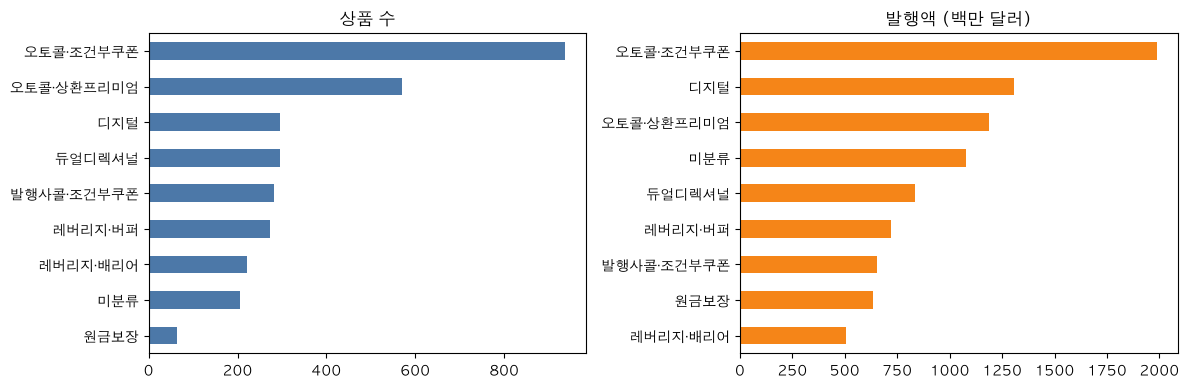

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fam.상품수.sort_values().plot(kind="barh", ax=axes[0], title="상품 수", color="#4c78a8")
fam.발행액_백만달러.sort_values().plot(kind="barh", ax=axes[1], title="발행액 (백만 달러)", color="#f58518")
for ax in axes:
    ax.set_ylabel("")
plt.tight_layout()

발행액 중앙값 $1.11M, 평균 $2.83M
상위 10% 상품이 발행액의 54%, 상위 1%가 19%


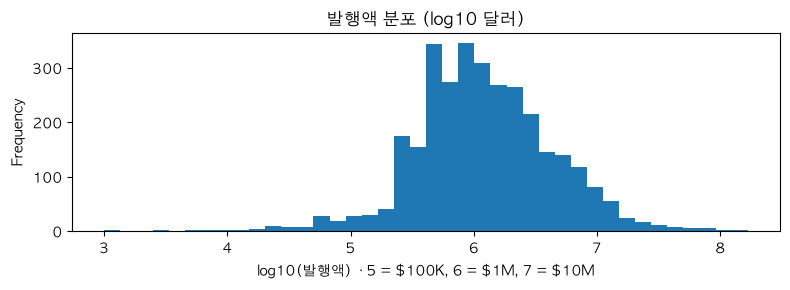

In [4]:
# 발행 규모의 집중도: 소수의 대형 발행이 대부분을 차지한다
v = df.principal_amount_usd.dropna().sort_values(ascending=False).reset_index(drop=True)
top10, top1 = v.head(int(len(v) * 0.1)).sum() / v.sum(), v.head(int(len(v) * 0.01)).sum() / v.sum()
print(f"발행액 중앙값 ${v.median() / 1e6:.2f}M, 평균 ${v.mean() / 1e6:.2f}M")
print(f"상위 10% 상품이 발행액의 {top10:.0%}, 상위 1%가 {top1:.0%}")
ax = np.log10(v).plot(kind="hist", bins=40, figsize=(8, 3), title="발행액 분포 (log10 달러)")
ax.set_xlabel("log10(발행액)  · 5 = $100K, 6 = $1M, 7 = $10M")
plt.tight_layout()

> **읽는 법**: 건수로는 오토콜 상품이 압도적이지만 **건당 규모는 작습니다**(중앙값 약 $100만). 개별 자문사·고객 맞춤형 소액 발행이 대부분이고, 발행액의 절반 이상은 상위 10%의 대형 발행이 만듭니다. "가장 많이 파는 상품"을 말할 때 건수와 금액 중 무엇을 기준으로 할지 먼저 정해야 합니다.

## 2. 누구를 통해 파나: 판매 채널

JPM이 발행한 노트는 JPM 자체 채널(JPMS) 외에 **경쟁 은행의 자산관리 플랫폼**으로도 팔립니다. 공시의 판매 문구(Plan of Distribution)로 채널을 판별했습니다(`db.CHANNEL_RULES`).

In [5]:
ch = (df.groupby("channel")
        .agg(상품수=("cusip", "size"), 발행액_백만달러=("principal_amount_usd", lambda s: s.sum() / 1e6),
             건당중앙값_백만달러=("principal_amount_usd", lambda s: s.median() / 1e6),
             평균추정가치=("estimated_value_per_1000", "mean"), 연환산마진=("margin_pa", "mean"),
             FWP비율=("fwp_count", lambda s: (s > 0).mean()), 평균판매일수=("marketing_days", "mean"))
        .sort_values("발행액_백만달러", ascending=False).round(2))
ch

,상품수,발행액_백만달러,건당중앙값_백만달러,평균추정가치,연환산마진,FWP비율,평균판매일수
channel,,,,,,,
JPMS,2830,6949.93,1.00,957.37,13.25,0.10,11.93
UBS,125,773.21,4.78,966.51,11.32,0.00,6.78
Morgan Stanley,77,696.50,6.40,961.17,15.72,0.78,11.21
Goldman Sachs,38,329.85,5.99,991.51,5.00,0.00,5.89
Wells Fargo,76,150.63,1.48,954.28,20.37,0.91,8.09


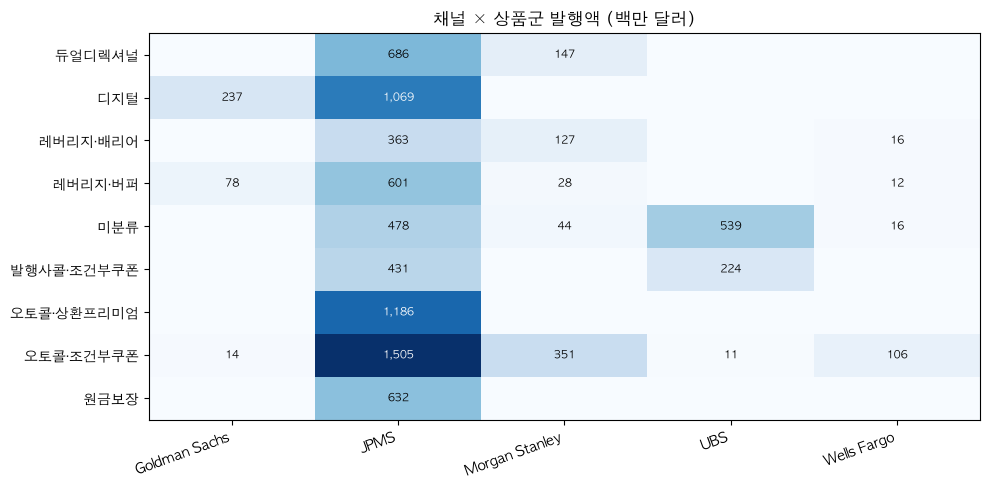

In [6]:
heat = df.pivot_table(index="family_ko", columns="channel", values="principal_amount_usd", aggfunc="sum").fillna(0) / 1e6
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(heat.columns)), heat.columns, rotation=20, ha="right")
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = heat.values[i, j]
        if val > 0:
            ax.text(j, i, f"{val:,.0f}", ha="center", va="center", fontsize=8, color="white" if val > heat.values.max() / 2 else "black")
ax.set_title("채널 × 상품군 발행액 (백만 달러)")
plt.tight_layout()

**읽는 법**
- **외부 플랫폼은 건당 규모가 5~6배 큽니다.** UBS·Morgan Stanley·Goldman 채널은 자문사가 여러 고객 주문을 모아 한 번에 발행하는 구조로 보입니다.
- **Goldman 채널은 추정가치가 $990대로 수수료가 거의 없습니다.** 만기도 짧고(약 2년) 디지털 상품이 대부분입니다. 수수료 기반 자문 계좌용 "기관형" 가격입니다.
- **판매 방식이 다릅니다.** Morgan Stanley·Wells Fargo는 FWP(판매용 텀시트)를 대부분 내고, UBS·Goldman은 내지 않습니다(수수료 기반 계좌 배정).
- 채널마다 주력 상품이 다릅니다. UBS는 발행사콜·쿠폰 상품과 자체 형식 상품, Morgan Stanley는 오토콜과 듀얼디렉셔널, Goldman은 디지털 중심입니다.

## 3. 무엇에 연동하나: 기초자산

기초자산을 다섯 그룹으로 묶었습니다 (`analysis.underlying_group`).

| 그룹 | 예 |
|---|---|
| **광역지수** | S&P 500, Russell 2000, Nasdaq-100, Dow Jones, EURO STOXX 50 |
| **전략지수** | MerQube Vol Advantage, J.P. Morgan Multi-Asset, Risk Control 지수처럼 **차감·변동성 제어가 내장된 규칙 기반 지수** |
| **개별주식** | Amazon, NVIDIA, Palantir … |
| **ETF** | EFA, QQQ, 섹터 ETF, 비트코인 ETF |
| **혼합·금리·기타** | 지수+ETF 혼합, 금리 연계, 고정금리 콜러블 |

In [7]:
grp = (df.groupby("und_group")
         .agg(상품수=("cusip", "size"), 발행액_백만달러=("principal_amount_usd", lambda s: s.sum() / 1e6),
              평균만기=("tenor_years", "mean"), 평균쿠폰=("coupon_rate_pa", "mean"),
              평균추정가치=("estimated_value_per_1000", "mean"), 연환산마진=("margin_pa", "mean"))
         .sort_values("상품수", ascending=False).round(3))
grp

,상품수,발행액_백만달러,평균만기,평균쿠폰,평균추정가치,연환산마진
und_group,,,,,,
광역지수,1491,4266.199,3.112,0.094,971.456,10.298
전략지수,657,985.308,5.011,0.133,918.689,16.913
개별주식,508,999.481,2.125,0.154,964.527,18.240
금리·기타,215,1865.547,3.321,0.050,965.418,11.993
혼합,181,620.213,3.132,0.109,964.488,12.554
ETF,94,163.364,2.877,0.115,965.254,12.820


In [8]:
from aifinance.analysis import FULL_DB
import duckdb

con = duckdb.connect(str(FULL_DB), read_only=True)
top_und = con.execute('''
    SELECT coalesce(u.ticker, u.name) AS 기초자산, u.kind, count(DISTINCT p.cusip) AS 상품수,
           round(sum(p.principal_amount_usd) / 1e6) AS 발행액_백만달러
    FROM products p JOIN underlyings u ON u.accession_number = p.final_accession
    GROUP BY ALL ORDER BY 상품수 DESC LIMIT 20''').df()
con.close()
top_und

,기초자산,kind,상품수,발행액_백만달러
0,SPX,index,955,2769.0
1,RTY,index,828,1822.0
2,NDX,index,505,971.0
3,INDU,index,349,830.0
4,MQUSTVA,index,298,342.0
5,MQUSLVA,index,275,466.0
6,SX5E,index,182,674.0
7,SPXFP,index,164,285.0
8,NDXT,index,161,289.0
9,EFA,etf,52,124.0


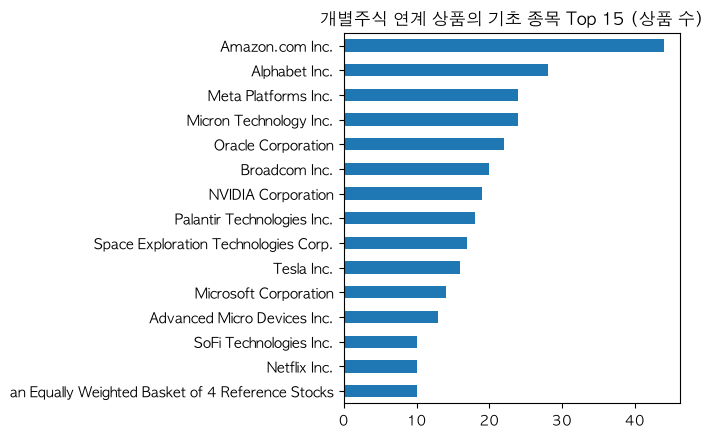

In [9]:
stocks = df[df.und_group == "개별주식"].underlying_names.str.split(" / ").explode()
stocks = stocks.str.replace(r"^(?:Class A )?(?:Common Stock|Ordinary Shares|American Depositary Shares) of ", "", regex=True)
ax = stocks.value_counts().head(15).sort_values().plot(kind="barh", figsize=(7, 4.5), title="개별주식 연계 상품의 기초 종목 Top 15 (상품 수)")
ax.set_ylabel("")
plt.tight_layout()

**읽는 법**
- 상품 수로는 **광역지수가 절반**입니다. 특히 S&P 500·Russell 2000·Nasdaq-100을 묶은 워스트오브가 주력입니다.
- **전략지수 상품이 약 1/5**이나 됩니다. 만기가 평균 5년으로 가장 길고, 추정가치는 가장 낮습니다(5절).
- 개별주식은 **AI·반도체·대형 기술주**에 몰려 있고, SpaceX 같은 화제 종목도 기초자산으로 등장합니다. 고객 관심이 큰 종목을 빠르게 상품화하는 것도 경쟁력입니다.

## 4. 어떤 조건인가: 오토콜 조건부 쿠폰 상품

가장 많이 팔리는 오토콜 조건부 쿠폰 상품의 조건을 기초자산 그룹별로 봅니다.

> ⚠️ **교란 주의**: 전체를 한꺼번에 보면 "배리어가 낮을수록(안전할수록) 쿠폰이 높다"는 거꾸로 된 결과가 나옵니다. 낮은 배리어가 변동성이 큰 개별주식·전략지수 상품에 몰려 있기 때문입니다. **반드시 기초자산 그룹 안에서 비교**해야 합니다.

In [10]:
ac = df[df.product_family == "autocall_contingent_coupon"]
print("전체를 섞어 본 배리어별 쿠폰 (교란된 결과):")
display(ac.groupby(ac.barrier_pct.round(2)).agg(n=("cusip", "size"), 평균쿠폰=("coupon_rate_pa", "mean")).query("n >= 15").round(3).T)

terms = (ac.groupby(["und_group", "basket_type"])
           .agg(n=("cusip", "size"), 평균쿠폰=("coupon_rate_pa", "mean"), 평균배리어=("barrier_pct", "mean"),
                평균만기=("tenor_years", "mean"), 메모리비율=("memory_coupon", "mean"), 연환산마진=("margin_pa", "mean"))
           .query("n >= 10").round(3))
terms

전체를 섞어 본 배리어별 쿠폰 (교란된 결과):


barrier_pct,0.50,0.55,0.60,0.65,0.70,0.75,0.80
n,214.000,16.000,185.00,38.000,120.000,29.000,20.000
평균쿠폰,0.147,0.124,0.13,0.117,0.101,0.118,0.101


n   평균쿠폰  평균배리어   평균만기  메모리비율   연환산마진
und_group basket_type                                         
ETF       worst_of      13  0.123  0.595  2.392  0.583  14.488
개별주식      single       225  0.144  0.572  2.227  0.579  17.632
          worst_of      60  0.179    NaN  2.784  0.771  18.907
광역지수      single        24  0.150  0.803  2.124    0.0  11.121
          worst_of     144  0.090  0.686  2.603  0.061  14.615
금리·기타     single        21    NaN  0.631  2.570   <NA>  16.336
          worst_of      21    NaN  0.705  2.952   <NA>  15.362
전략지수      single       390  0.134  0.550  4.990  0.369  16.317
혼합        worst_of      32  0.109  0.610  2.644  0.258  14.240

In [11]:
print("조기상환 · 쿠폰 관찰 빈도")
display(pd.crosstab(ac.autocall_frequency.fillna("미상"), ac.coupon_frequency.fillna("미상"), margins=True))
print("첫 조기상환 기준(최초가 대비)")
ac.autocall_trigger_pct.round(2).value_counts().head(6)

조기상환 · 쿠폰 관찰 빈도


coupon_frequency,annual,monthly,quarterly,semiannual,미상,All
autocall_frequency,,,,,,
annual,1,0,0,0,52,53
monthly,0,467,0,0,7,474
quarterly,0,0,249,0,22,271
semiannual,0,0,0,4,4,8
미상,0,0,0,0,132,132
All,1,467,249,4,217,938


첫 조기상환 기준(최초가 대비)


autocall_trigger_pct
1.00    576
0.90     19
0.95      9
0.93      5
1.01      5
0.97      2
Name: count, dtype: int64

**읽는 법**
- 같은 그룹 안에서는 통념대로 **워스트오브가 단일보다 쿠폰이 높습니다**(개별주식: 워스트오브 약 18% vs 단일 약 14%).
- **광역지수 워스트오브**(쿠폰 약 9%, 배리어 약 70%, 만기 약 2.6년)가 JPM의 표준 상품입니다.
- **전략지수 단일 상품**은 쿠폰 약 13%를 주지만 배리어가 낮고(약 55%) 만기가 깁니다(약 5년). 지수 자체의 연 6% 차감이 높은 쿠폰의 재원입니다(모듈 5 e3 답변).
- 관찰은 월간이 주류이고, 조기상환 기준은 대부분 최초가 100%입니다. 메모리 쿠폰은 약 1/3만 붙습니다.

## 5. 얼마나 남기나: 추정가치로 본 발행 마진

JPM은 공시에 **추정가치(estimated value)**를 밝힙니다. 발행가 $1,000과의 차이를 **마진**이라고 부르겠습니다. 여기에는 판매 수수료, 구조화·헤지 비용, 예상 헤지 이익이 모두 들어 있습니다(모듈 5 e1 답변).

만기가 긴 상품일수록 총마진이 커지는 것은 당연하므로, **연 환산 마진**(총마진 ÷ 만기)도 함께 봅니다.

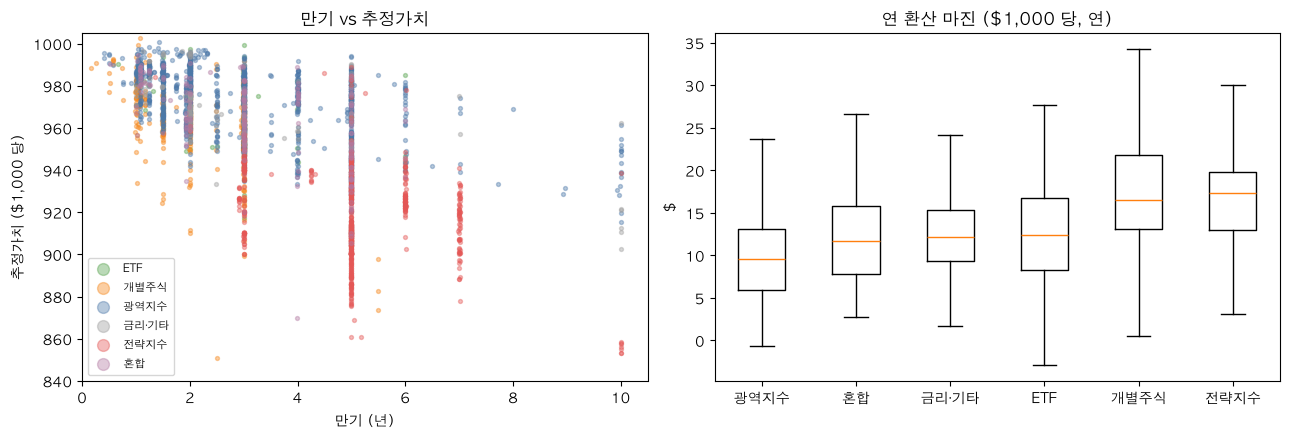

In [12]:
colors = {"광역지수": "#4c78a8", "전략지수": "#e45756", "개별주식": "#f58518", "ETF": "#54a24b", "혼합": "#b279a2", "금리·기타": "#9d9d9d"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for g, d in df.dropna(subset=["tenor_years", "estimated_value_per_1000"]).groupby("und_group"):
    axes[0].scatter(d.tenor_years, d.estimated_value_per_1000, s=8, alpha=0.4, label=g, color=colors.get(g))
axes[0].set(xlabel="만기 (년)", ylabel="추정가치 ($1,000 당)", title="만기 vs 추정가치", ylim=(840, 1005), xlim=(0, 10.5))
axes[0].legend(markerscale=3, fontsize=8)

order = df.groupby("und_group").margin_pa.median().sort_values().index
data = [df.loc[df.und_group == g, "margin_pa"].dropna().clip(upper=60) for g in order]
axes[1].boxplot(data, tick_labels=order, showfliers=False)
axes[1].set(title="연 환산 마진 ($1,000 당, 연)", ylabel="$")
plt.tight_layout()

In [13]:
mg = (df.groupby(["und_group"])
        .agg(n=("cusip", "size"), 총마진=("margin", "mean"), 연환산마진=("margin_pa", "mean"), 평균만기=("tenor_years", "mean"))
        .sort_values("총마진", ascending=False).round(1))
mg["마진×발행액_백만달러"] = (df.assign(m=df.margin / 1000 * df.principal_amount_usd).groupby("und_group").m.sum() / 1e6).round(1)
mg

,n,총마진,연환산마진,평균만기,마진×발행액_백만달러
und_group,,,,,
전략지수,657,81.3,16.9,5.0,77.1
혼합,181,35.5,12.6,3.1,19.4
개별주식,508,35.5,18.2,2.1,27.8
ETF,94,34.7,12.8,2.9,5.2
금리·기타,215,34.6,12.0,3.3,45.7
광역지수,1491,28.5,10.3,3.1,98.9


In [14]:
# 추정가치가 가장 낮은 상품 10개
df.nsmallest(10, "estimated_value_per_1000")[["cusip", "family_ko", "underlying_names", "tenor_years", "estimated_value_per_1000", "channel"]]

,cusip,family_ko,underlying_names,tenor_years,estimated_value_per_1000,channel
1237,46661QNX9,오토콜·조건부쿠폰,Common Stock of Iovance Biotherapeutics Inc.,2.51,850.9,JPMS
1222,46661PSU2,오토콜·상환프리미엄,MQUSLVA,10.00,853.3,JPMS
2372,46661PSV0,오토콜·상환프리미엄,MQUSLVA,10.00,853.3,JPMS
779,46661PQU4,오토콜·상환프리미엄,MQUSLVA,10.00,855.0,JPMS
1244,46661PCH8,오토콜·상환프리미엄,MQUSLVA,10.00,856.0,JPMS
806,46661PCK1,오토콜·상환프리미엄,MQUSLVA,10.00,857.3,JPMS
2395,46661PCF2,오토콜·상환프리미엄,MQUSLVA,10.00,857.8,JPMS
1811,46661PSW8,오토콜·상환프리미엄,MQUSLVA,10.00,858.4,JPMS
1068,46661MJ62,레버리지·배리어,MQUSLVA,5.00,860.7,JPMS
757,46661CJP2,레버리지·배리어,MQUSLVA,5.17,860.8,JPMS


**읽는 법**
- **전략지수 상품의 총마진은 약 $81로 광역지수(약 $29)의 세 배 가까이 됩니다.** 연 환산으로는 차이가 줄지만 여전히 높습니다(약 $17 vs $10). 긴 만기와 높은 연 마진이 겹쳐, 발행액 대비 마진 기여도가 상품 수 비중보다 큽니다.
- **개별주식 상품은 연 환산 마진이 가장 높습니다**(약 $18). 만기가 짧아 총마진은 중간 수준입니다.
- 채널별로는 Goldman 채널이 마진이 가장 얇고, Wells Fargo 채널이 연 환산으로 가장 두껍습니다(2절 표).

> 추정가치는 **JPM 내부 모형**의 값입니다. 다른 발행사와 산정 방식이 달라 직접 비교에는 주의가 필요합니다. 그래도 같은 발행사 안에서 상품 간 비교에는 유용한 지표입니다.

## 6. 시간에 따른 변화

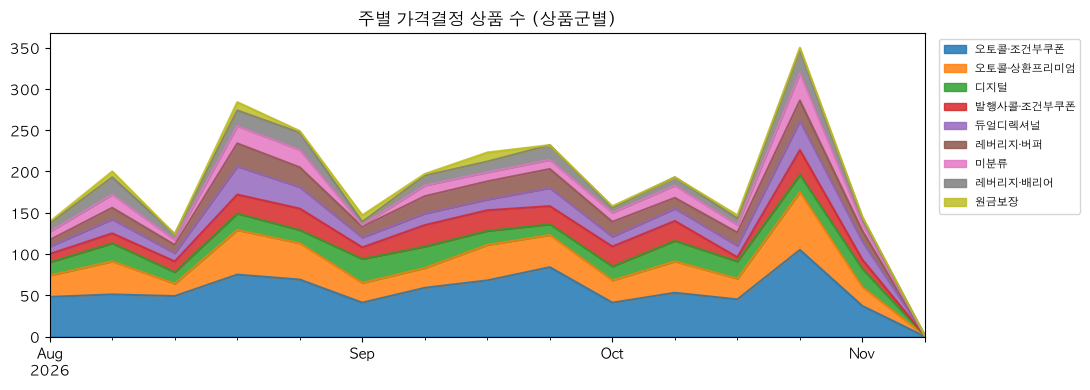

In [15]:
weekly = df[df.pricing_date >= "2026-08-01"].pivot_table(index="pricing_week", columns="family_ko", values="cusip", aggfunc="count").fillna(0)
weekly = weekly[weekly.sum().sort_values(ascending=False).index]
ax = weekly.plot(kind="area", stacked=True, figsize=(11, 4), alpha=0.85, title="주별 가격결정 상품 수 (상품군별)")
ax.set_xlabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

In [16]:
# 표준 상품(광역지수 3종 워스트오브 오토콜)의 쿠폰 추이: 같은 구조끼리 비교해야 시장 변화가 보인다
std = ac[(ac.underlying_names == "NDX / RTY / SPX") & (ac.pricing_date >= "2026-08-01")]
trend = std.groupby("pricing_week").agg(n=("cusip", "size"), 평균쿠폰=("coupon_rate_pa", "mean"), 평균배리어=("barrier_pct", "mean")).round(4)
trend

,n,평균쿠폰,평균배리어
pricing_week,,,
2026-08-03,4,0.0909,0.6333
2026-08-10,7,0.0914,0.6857
2026-08-24,4,0.0831,0.7000
2026-08-31,7,0.0919,0.6929
2026-09-07,1,0.0985,0.7000
2026-09-14,3,0.0822,0.7000
2026-09-21,4,0.0810,0.7000
2026-09-28,3,0.0908,0.6667
2026-10-12,2,0.0862,0.7000


**읽는 법**: 주별 발행 수는 월말이 낀 주에 많아지는 경향이 보입니다. 표준 상품(NDX/RTY/SPX 워스트오브)의 쿠폰은 연 8~9%대에서 크게 움직이지 않았습니다. 시장 변동성이나 금리 변화와 연결하려면 외부 시장 데이터가 필요합니다(실습 6-C).

## 7. 경쟁사 분석 메모: JP Morgan 구조화 노트 (2026년 8~11월)

위 분석을 실무 메모로 요약하면 이렇습니다. (숫자는 이 노트북 실행 결과 기준)

**1. 대량·소액·맞춤형 공장.** 약 3개월 반 동안 3천여 개 상품, 약 89억 달러를 발행했습니다. 건당 중앙값은 약 $100만이고 매주 150~300개를 찍어 냅니다. 표준화된 템플릿과 자동화된 공시 체계가 뒷받침합니다.

**2. 주력은 "광역지수 워스트오브 오토콜", 마진 엔진은 "전략지수".** 상품 수의 절반이 S&P 500·Russell 2000·Nasdaq-100 기반입니다. 반면 MerQube·JPM 브랜드 전략지수 상품은 만기가 길고 추정가치가 낮아(평균 약 $919), 상품 수 대비 마진 기여가 큽니다. 지수에 내장된 연 6% 차감으로 높은 쿠폰을 "만들어" 내는 구조입니다.

**3. 경쟁사 플랫폼에도 공급한다.** UBS·Morgan Stanley·Wells Fargo·Goldman 채널로도 팔고, 이 채널은 건당 규모가 5~6배 큽니다. Goldman 채널은 수수료 없는 기관형 가격(추정가치 약 $990)입니다. **채널별로 가격과 상품을 달리하는 이원 전략**입니다.

**4. 테마 대응이 빠르다.** AI·반도체 대형주, SpaceX 같은 화제 종목, 비트코인 ETF가 기초자산에 등장합니다.

**5. 판매 중 조건은 거의 바뀌지 않는다.** 확정 쿠폰의 97%가 예비본 하한 그대로입니다. 시장이 유리하게 움직인 이익은 투자자 쿠폰이 아닌 다른 곳(마진)으로 갔을 가능성이 있습니다(검증 필요).

### 모듈 7로 가져갈 가설 (신상품 기회)
- **H1**: 전략지수 상품의 높은 쿠폰은 투자자가 지수 차감 비용을 잘 모르기 때문일 수 있다 → **차감이 투명한 대안 지수 상품**의 여지
- **H2**: 광역지수 워스트오브 시장은 JPM 표준 상품이 장악했다 → 같은 구조로 정면 승부하기보다 **조건(메모리, 스텝다운, 관찰 빈도)으로 차별화**
- **H3**: 개별 테마주 상품은 연 마진이 높고 만기가 짧다 → **테마 바스켓**(예: AI 인프라 3종 워스트오브)을 빠르게 출시하는 역량이 경쟁력
- **H4**: 외부 플랫폼용 대형·저수수료 상품 수요가 있다 → 자문사 채널용 **기관형 가격의 단순 구조** 상품

## 🤖 Claude 실습 6

**6-A. MCP로 분석 질문하기** (Claude Desktop, `aifinance` 연결)
> JP Morgan이 지난 3개월 동안 개별주식 연계 오토콜 상품에서 가장 많이 쓴 종목 10개와, 종목별 평균 쿠폰·배리어·만기·추정가치를 표로 보여줘. 쿠폰이 가장 높은 종목 3개는 그 이유를 공시의 위험 고지에서 찾아 설명해줘.

**6-B. 경쟁사 분석 메모 검증**
> 노트북 06의 7절 "경쟁사 분석 메모"의 주장 5개를 하나씩 DB와 공시 원문으로 검증해줘. 각 주장마다 근거가 된 SQL과 결과, 반례가 있으면 반례도 보여주고 "지지됨 / 부분적으로 지지됨 / 지지 안 됨"으로 판정해줘.

**6-C. 시장 데이터 결합** (Code 탭)
> 표준 상품(NDX/RTY/SPX 워스트오브 오토콜)의 주별 평균 쿠폰을 같은 기간 VIX·RVX와 미국 2년 국채금리 주간 평균과 비교하는 차트를 만들어줘. 공개 데이터 소스를 쓰고 출처를 밝혀줘. 상관관계가 있다면 그 크기와 한계를 설명해줘.

**6-D. 다른 발행사로 확장** (Code 탭)
> `aifinance.pipeline`을 다른 발행사(예: GS Finance Corp., Morgan Stanley Finance LLC)에도 쓸 수 있도록 CIK를 인자로 받게 바꾸고, 한 곳을 2주치만 수집해 JPM과 상품군·추정가치 분포를 비교해줘. 추출기가 그 발행사 형식에서 얼마나 맞는지 품질 점검 결과도 함께 보여줘.

---
**다음 모듈**: 모듈 7에서는 위 가설 중 하나를 골라 **신상품을 설계**합니다. 몬테카를로 시뮬레이션으로 상품 가치와 쿠폰 수준을 정하고, 과거 데이터로 백테스트하고, JPM 경쟁 상품과 비교한 텀시트 초안을 씁니다.